# 04 — Collaborative Filtering and Offline Evaluation

Notebooks 02 and 03 built recommenders from book **metadata** (authors, tags) and
judged them on a couple of examples. This notebook answers the question they left
open: **which model recommends best, measured on real reader behaviour?**

It does two things:
1. builds a new model, **item-based collaborative filtering**, the first one to use the
   ~6 million ratings: two books are similar if the same readers liked them;
2. sets up an **offline evaluation protocol** and applies it to every model of the project.

| Model | Uses | Notebook |
| --- | --- | --- |
| Random | nothing (sanity check) | 04 |
| Popularity | number of readers who liked each book | 02 (recomputed here on training data) |
| Content-based | TF-IDF of authors + tags | 02 |
| k-means | tag clusters (genres) | 03 |
| Item-based collaborative filtering | ratings | 04 |

In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from sklearn.feature_extraction.text import TfidfVectorizer, TfidfTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
})
COLOR, GREY = "#3b6fb6", "#b8bcc4"

RANDOM_STATE = 42
DATA = "../data"

In [2]:
books = pd.read_csv(f"{DATA}/books.csv")
ratings = pd.read_csv(f"{DATA}/ratings.csv")
tags = pd.read_csv(f"{DATA}/tags.csv")
book_tags = pd.read_csv(f"{DATA}/book_tags.csv")

# book_id runs from 1 to 10,000 in the same order as books.csv: book_id - 1 is the row index
assert (books["book_id"].values == np.arange(1, len(books) + 1)).all()
ratings["item"] = ratings["book_id"] - 1
ratings["user"] = ratings["user_id"] - 1

n_users, n_books = ratings["user"].max() + 1, len(books)
print(f"{n_users:,} users, {n_books:,} books, {len(ratings):,} ratings")

53,424 users, 10,000 books, 5,976,479 ratings


## 1. Evaluation protocol

**What counts as a good recommendation?** A book the reader *liked*, i.e. rated 4 or 5 stars.

**Train/test split.** For every reader, 20 % of the books they liked are hidden: this is
the **test set**. All their other ratings form the **training set**. Models only see the
training set, recommend 10 books per reader, and we check how many hidden books they find.

Every model receives exactly the same data, so the comparison is fair. In particular,
popularity is recomputed from the training set: using `ratings_count` from `books.csv`
would leak information about the hidden books.

In [3]:
liked = ratings[ratings["rating"] >= 4]
test = liked.groupby("user", group_keys=False).sample(frac=0.2, random_state=RANDOM_STATE)
train = ratings.drop(test.index)

print(f"Training ratings: {len(train):,}")
print(f"Hidden liked books (test): {len(test):,}")
print(f"Overlap between train and test: {len(train.index.intersection(test.index))}")

Training ratings: 5,152,078
Hidden liked books (test): 824,401


Overlap between train and test: 0


Two sparse user × book matrices summarise the training set:
- `LIKED`: 1 if the user liked the book in the training set — the input of every model;
- `SEEN`: 1 if the user rated the book in the training set — these books are never recommended again.

In [4]:
def user_book_matrix(df):
    values = np.ones(len(df), dtype=np.float32)
    return sp.csr_matrix((values, (df["user"], df["item"])), shape=(n_users, n_books))

LIKED = user_book_matrix(train[train["rating"] >= 4])
SEEN = user_book_matrix(train)

**Metrics**, computed for each reader and averaged:

- **precision@10** = hidden liked books among the 10 recommendations / 10
- **recall@10** = hidden liked books among the 10 recommendations / number of hidden liked books
- **coverage** = share of the catalogue recommended to at least one reader. A model can score
  well while recommending the same few bestsellers to everyone; coverage reveals it.

To keep computations fast, we evaluate on samples of readers. Two **disjoint** samples are drawn:
5,000 **validation** readers to tune hyperparameters, and 5,000 **test** readers for the final
scores. Tuning on the readers used for the final scores would make the results optimistic.

In [5]:
candidates = test["user"].unique()
rng = np.random.default_rng(RANDOM_STATE)
sampled = rng.choice(candidates, 10_000, replace=False)
val_users, test_users = np.sort(sampled[:5_000]), np.sort(sampled[5_000:])

hidden = test.groupby("user")["item"].apply(set)


def top_n(scores, users, n=10):
    """Indices of the n best-scored books per user, excluding books seen in training."""
    scores = np.where(SEEN[users].toarray() > 0, -np.inf, np.asarray(scores, dtype=np.float32))
    best = np.argpartition(-scores, n, axis=1)[:, :n]
    order = np.argsort(-np.take_along_axis(scores, best, axis=1), axis=1)
    return np.take_along_axis(best, order, axis=1)


def evaluate(recs, users):
    """Precision@10, recall@10 and catalogue coverage of a (users × 10) array of recommendations."""
    hits = np.array([len(hidden[u].intersection(r)) for u, r in zip(users, recs)])
    sizes = np.array([len(hidden[u]) for u in users])
    return {"precision@10": (hits / recs.shape[1]).mean(),
            "recall@10": (hits / sizes).mean(),
            "coverage": len(np.unique(recs)) / n_books}

print(f"Hidden liked books per test reader: median {hidden.loc[test_users].apply(len).median():.0f}")

Hidden liked books per test reader: median 15


## 2. Baselines: random and popularity

- **Random** gives the floor: any useful model must be far above it.
- **Popularity** recommends the books liked by the most readers in the training set, minus
  the ones the reader has already rated. It is not personalised, but often hard to beat.

In [6]:
results = {}

random_scores = np.random.default_rng(0).random((len(test_users), n_books))
results["Random"] = evaluate(top_n(random_scores, test_users), test_users)

popularity = np.asarray(LIKED.sum(axis=0)).ravel()
results["Popularity"] = evaluate(top_n(popularity[None, :], test_users), test_users)  # same scores for every reader

pd.DataFrame(results).T.round(3)

,precision@10,recall@10,coverage
Random,0.002,0.001,0.992
Popularity,0.077,0.051,0.004


## 3. Item-based collaborative filtering

**Idea.** Each book is represented by the set of readers who liked it (a column of `LIKED`).
Two books are similar when they are liked by the same readers — whatever their tags or authors.

**Similarity.** Cosine similarity between the book vectors: the columns are normalised, then a
dot product counts shared readers relative to each book's popularity.

**Neighbours.** The full book × book matrix has 100 million cells. As is standard, we only keep
the *k* most similar books of each book (its **neighbours**), which removes weak, noisy similarities.
The matrix is computed in blocks of 1,000 books to limit memory use.

**Scoring.** For a reader, the score of a candidate book is the sum of its similarities with the
books the reader liked:

$$
\text{score}(u, i) = \sum_{j \,\in\, \text{liked}(u)} \text{sim}_k(i, j)
$$

where $\text{sim}_k(i, j)$ is non-zero only if $j$ is among the $k$ neighbours of $i$.
In matrix form, the scores of all users are `LIKED @ S.T`.

In [7]:
def neighbour_matrix(similarity_block, k, block=1_000):
    """Sparse book × book matrix keeping the k most similar books of each book.

    similarity_block(a, b) must return the dense similarities between books a..b-1 and all books.
    """
    rows, cols, vals = [], [], []
    for start in range(0, n_books, block):
        stop = min(start + block, n_books)
        sim = np.asarray(similarity_block(start, stop), dtype=np.float32)
        sim[np.arange(stop - start), np.arange(start, stop)] = 0  # a book is not its own neighbour
        best = np.argpartition(-sim, k, axis=1)[:, :k]
        rows.append(np.repeat(np.arange(start, stop), k))
        cols.append(best.ravel())
        vals.append(np.take_along_axis(sim, best, axis=1).ravel())
    S = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))),
                      shape=(n_books, n_books))
    S.eliminate_zeros()
    return S


def recommend_from_neighbours(S, users):
    """Top-10 books per user: sum of similarities with the books they liked."""
    return top_n((LIKED[users] @ S.T).toarray(), users)


# books × users, each row normalised: a dot product between two rows is a cosine similarity
book_vectors = normalize(LIKED.T.tocsr())
cf_similarity = lambda a, b: (book_vectors[a:b] @ book_vectors.T).toarray()

### Readers who liked *The Hunger Games* also liked…

Before evaluating, a sanity check on one book: its 10 nearest neighbours by shared readers.

In [8]:
def similar_books(S, title, n=10):
    i = books[books["title"].str.contains(title, case=False, regex=False)] \
        .sort_values("ratings_count", ascending=False).index[0]
    row = S.getrow(i)
    best = row.indices[np.argsort(-row.data)][:n]
    return books.loc[best, ["title", "authors"]].assign(similarity=row[0, best].toarray().ravel().round(3))

S_cf = neighbour_matrix(cf_similarity, k=50)
similar_books(S_cf, "The Hunger Games")

,title,authors,similarity
16,"Catching Fire (The Hunger Games, #2)",Suzanne Collins,0.536
19,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,0.471
1,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré",0.425
11,"Divergent (Divergent, #1)",Veronica Roth,0.369
30,The Help,Kathryn Stockett,0.334
24,Harry Potter and the Deathly Hallows (Harry Po...,"J.K. Rowling, Mary GrandPré",0.333
2,"Twilight (Twilight, #1)",Stephenie Meyer,0.329
20,Harry Potter and the Order of the Phoenix (Har...,"J.K. Rowling, Mary GrandPré",0.328
17,Harry Potter and the Prisoner of Azkaban (Harr...,"J.K. Rowling, Mary GrandPré, Rufus Beck",0.322
26,Harry Potter and the Half-Blood Prince (Harry ...,"J.K. Rowling, Mary GrandPré",0.321


The neighbours are found from ratings only, yet they make sense: the rest of the trilogy, then
other young-adult series read by the same audience (*Harry Potter*, *Divergent*, *Twilight*).
*The Help*, a bestseller from another genre, shows a known side effect: collaborative filtering
also captures plain popularity, since very popular books share readers with everything.
Unlike the content-based model, collaborative filtering can link books whose tags differ but
whose readers overlap.

### Choosing the number of neighbours *k* (validation readers)

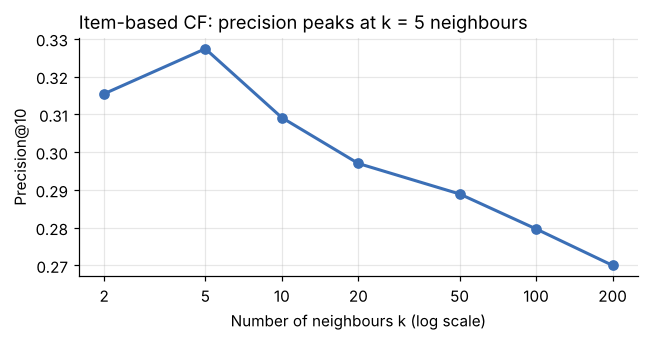

Best k on validation readers: 5


In [9]:
K_GRID = [2, 5, 10, 20, 50, 100, 200]

def tune_k(similarity_block):
    scores = {}
    for k in K_GRID:
        recs = recommend_from_neighbours(neighbour_matrix(similarity_block, k), val_users)
        scores[k] = evaluate(recs, val_users)["precision@10"]
    return pd.Series(scores, name="precision@10 (validation)")

cf_tuning = tune_k(cf_similarity)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(cf_tuning.index, cf_tuning.values, marker="o", linewidth=2, color=COLOR)
ax.set_xscale("log")
ax.set_xticks(K_GRID, labels=[str(k) for k in K_GRID])
ax.minorticks_off()
ax.set_title(f"Item-based CF: precision peaks at k = {cf_tuning.idxmax()} neighbours")
ax.set_xlabel("Number of neighbours k (log scale)")
ax.set_ylabel("Precision@10")
plt.tight_layout()
plt.show()

best_k_cf = cf_tuning.idxmax()
print(f"Best k on validation readers: {best_k_cf}")

Precision peaks with very few neighbours: beyond that, distant neighbours add noise and
push popular books into everyone's list, while with only 2 neighbours too little information is kept. The value of *k* is chosen on validation readers only,
then frozen for the final evaluation.

In [10]:
S_cf = neighbour_matrix(cf_similarity, k=best_k_cf)
results["Item-based CF"] = evaluate(recommend_from_neighbours(S_cf, test_users), test_users)

## 4. Content-based and k-means models as personalised recommenders

The models of notebooks 02 and 03 answer "which books are similar to *this* book?".
To evaluate them on readers, we plug their similarity into exactly the same scoring as
collaborative filtering: neighbours of each book, then the sum over the books the reader liked.
Only the definition of similarity changes.

The features are rebuilt below with the same code as in notebooks 02 and 03.

In [11]:
# Content-based (notebook 02): TF-IDF on authors + 20 most frequent tags
SHELF_TAGS = {"to-read", "currently-reading", "favorites", "owned",
              "books-i-own", "default", "library", "kindle"}
bt = book_tags.merge(tags, on="tag_id")
top_tags = (bt[~bt["tag_name"].isin(SHELF_TAGS)]
            .sort_values("count", ascending=False).groupby("goodreads_book_id").head(20))
tag_text = top_tags.groupby("goodreads_book_id")["tag_name"].apply(" ".join)
content = (books["authors"].str.replace(" ", "_").str.replace(",_", " ") + " "
           + books["goodreads_book_id"].map(tag_text).fillna(""))
X_content = TfidfVectorizer(token_pattern=r"[^ ]+").fit_transform(content)

content_similarity = lambda a, b: (X_content[a:b] @ X_content.T).toarray()

In [12]:
# k-means (notebook 03): cleaned tags -> TF-IDF -> SVD -> k-means with k = 15
SHELF_PATTERN = (
    r"read|own|kindle|library|favou?rite|fav|ebook|e-book|audio|book-club|default|series|"
    r"buy|wish|tbr|\d{4}|shelf|have|borrowed|on-hold|dnf|did-not-finish|maybe|my-|books-i|"
    r"abandoned|unfinished|gave-up|recommended|novels?$|^books?$|^fiction$|^adult$|"
    r"^literature$|nook|calibre|amazon|free|gift|home|collection|keeper|stand-?alone"
)
bt3 = bt[~bt["tag_name"].str.contains(SHELF_PATTERN, regex=True) & (bt["count"] > 0)]
n_books_per_tag = bt3.groupby("tag_name")["goodreads_book_id"].nunique()
bt3 = bt3[bt3["tag_name"].isin(n_books_per_tag[n_books_per_tag >= 20].index)]

row_of_book = pd.Series(books.index, index=books["goodreads_book_id"])
tag_names = np.array(sorted(bt3["tag_name"].unique()))
col_of_tag = pd.Series(np.arange(len(tag_names)), index=tag_names)
counts = sp.csr_matrix((np.log1p(bt3["count"].values),
                        (row_of_book[bt3["goodreads_book_id"]].values, col_of_tag[bt3["tag_name"]].values)),
                       shape=(n_books, len(tag_names)))

X_tags = TfidfTransformer().fit_transform(counts)
Z = normalize(TruncatedSVD(n_components=100, random_state=RANDOM_STATE).fit_transform(X_tags)).astype(np.float32)
clusters = KMeans(n_clusters=15, n_init=10, random_state=RANDOM_STATE).fit(Z).labels_

# cosine similarity, set to zero between books of different clusters
kmeans_similarity = lambda a, b: (Z[a:b] @ Z.T) * (clusters[a:b, None] == clusters[None, :])

In [13]:
tuning = pd.DataFrame({"Content-based": tune_k(content_similarity),
                       "k-means": tune_k(kmeans_similarity),
                       "Item-based CF": cf_tuning})
tuning.index.name = "k"
tuning.round(3)

,Content-based,k-means,Item-based CF
k,,,
2,0.206,0.205,0.315
5,0.217,0.207,0.327
10,0.200,0.174,0.309
20,0.187,0.143,0.297
50,0.178,0.113,0.289
100,0.173,0.094,0.280
200,0.169,0.084,0.270


In [14]:
best_k = tuning.idxmax()

for name, similarity in [("Content-based", content_similarity), ("k-means", kmeans_similarity)]:
    S = neighbour_matrix(similarity, k=best_k[name])
    results[name] = evaluate(recommend_from_neighbours(S, test_users), test_users)

print("k chosen on validation readers:", best_k.to_dict())

k chosen on validation readers: {'Content-based': 5, 'k-means': 5, 'Item-based CF': 5}


## 5. Results on the test readers

In [15]:
order = ["Random", "Popularity", "k-means", "Content-based", "Item-based CF"]
summary = pd.DataFrame(results).T.loc[order]
summary.round(3)

,precision@10,recall@10,coverage
Random,0.002,0.001,0.992
Popularity,0.077,0.051,0.004
k-means,0.204,0.137,0.758
Content-based,0.214,0.145,0.652
Item-based CF,0.325,0.218,0.534


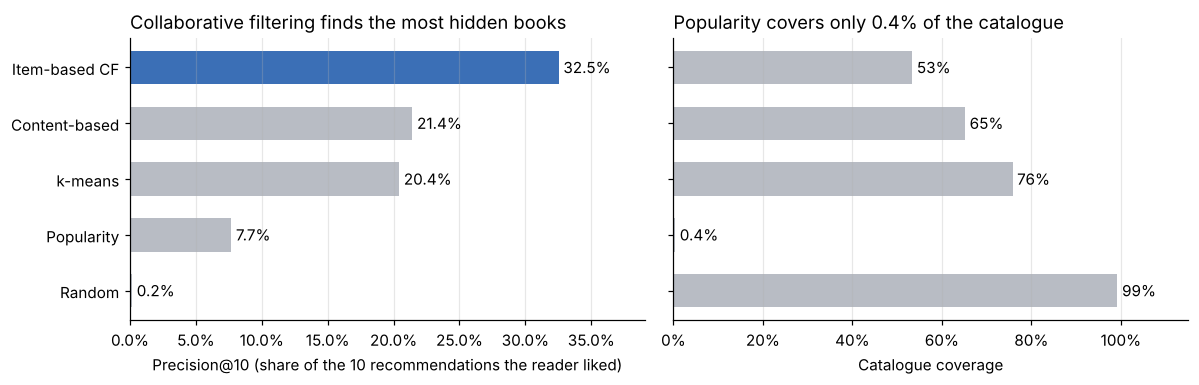

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

colors = [COLOR if name == "Item-based CF" else GREY for name in summary.index]
bars = axes[0].barh(summary.index, summary["precision@10"], color=colors, height=0.6)
axes[0].bar_label(bars, labels=[f"{v:.1%}" for v in summary["precision@10"]], padding=3)
axes[0].set_title("Collaborative filtering finds the most hidden books")
axes[0].set_xlabel("Precision@10 (share of the 10 recommendations the reader liked)")
axes[0].set_xlim(0, summary["precision@10"].max() * 1.2)

bars = axes[1].barh(summary.index, summary["coverage"], color=GREY, height=0.6)
axes[1].bar_label(bars, labels=[f"{v:.1%}" if v < 0.01 else f"{v:.0%}" for v in summary["coverage"]], padding=3)
axes[1].set_title(f"Popularity covers only {summary.loc['Popularity', 'coverage']:.1%} of the catalogue")
axes[1].set_xlabel("Catalogue coverage")
axes[1].set_xlim(0, 1.15)
axes[1].set_yticklabels([])

for ax in axes:
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
plt.tight_layout()
fig.savefig("../figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Example: recommendations for one reader

In [17]:
reader = test_users[0]

def titles(items):
    return books.loc[list(items), "title"].tolist()

liked_in_train = LIKED[reader].indices
print(f"Reader {reader + 1} liked {len(liked_in_train)} books in the training set, for example:")
for t in titles(liked_in_train[:8]):
    print("  -", t)

recs = recommend_from_neighbours(S_cf, np.array([reader]))[0]
pd.DataFrame({"recommended book": titles(recs),
              "hidden liked book?": ["yes" if i in hidden[reader] else "" for i in recs]},
             index=range(1, 11))

Reader 28 liked 68 books in the training set, for example:
  - The Hunger Games (The Hunger Games, #1)
  - To Kill a Mockingbird
  - The Catcher in the Rye
  - Catching Fire (The Hunger Games, #2)
  - Lord of the Flies
  - The Help
  - The Alchemist
  - The Giver (The Giver, #1)


,recommended book,hidden liked book?
1,Naked,
2,The Kite Runner,yes
3,Animal Farm,
4,Of Mice and Men,
5,The Lovely Bones,yes
6,Memoirs of a Geisha,
7,The Red Tent,
8,The Guernsey Literary and Potato Peel Pie Society,
9,Fierce Invalids Home from Hot Climates,
10,The Namesake,


## 7. Discussion

**Ranking.** Collaborative filtering clearly wins: on average, about 3 of its 10 recommendations
are books the reader actually liked, against fewer than 1 for popularity. Ratings carry
information that metadata does not: who reads what *together*.

**Content beats popularity.** The content-based model is almost three times as precise as popularity.
Readers of this dataset have already rated most bestsellers, so the "top 10" left for them is
weak, while similar authors and tags remain a strong signal.

**k-means is slightly below plain content-based similarity.** Restricting neighbours to the same
cluster cuts links across genres. With 5 neighbours the cost is small, because a book's closest
neighbours are usually in its own cluster anyway; with 200 neighbours, the gap is large
(see the tuning table). In exchange, k-means recommends a wider part of the catalogue.

**Coverage.** Popularity covers less than 1 % of the catalogue: everyone gets nearly the same list.
Personalised models spread recommendations across thousands of books.

**Limitations of this evaluation:**
- a book that was not hidden is not necessarily a bad recommendation: the reader may simply
  not have read it yet, so all precisions are **underestimates**, valid for *comparing* models;
- the split is random, not chronological: in reality, a model only knows the past;
- Goodbooks-10k only contains active readers (19 to 200 ratings each) and the 10,000 most popular
  books, so results may differ on a real catalogue with many new users and rare books (*cold start*).
